# Robot Visual Memory: graph image retrieval
Query an OpenEQA episode stored in Neo4j and inspect the returned visual evidence. Saved execution outputs are preserved.


In [1]:
import os
from pathlib import Path
from IPython.display import display, HTML
import pandas as pd
from rvm.io import read_json, load_config
from rvm.bundle import validate_bundle
SMOKE = os.getenv('RVM_NOTEBOOK_SMOKE') == '1'
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'pyproject.toml').is_file() and (p/'src/rvm').is_dir()), None)
if ROOT is None: raise RuntimeError('Open this notebook from the project checkout.')
BUNDLE = Path(os.getenv('RVM_BUNDLE', str(ROOT/'data/robot-visual-memory-graph')))
if SMOKE:
    from rvm.fixture import create_single_episode_fixture
    BUNDLE = create_single_episode_fixture(Path(os.environ['RVM_WORK'])/'local-graph', config_path=ROOT/'config.example.yaml')
bundle = validate_bundle(BUNDLE, show_progress=True)
frames, records = bundle['frames'], bundle['records']
config = read_json(BUNDLE/'selection.json').get('config', load_config(ROOT/'config.example.yaml'))
COLLECTION = config['retrieval']['collection']
ENVIRONMENT = frames[0].environment_id
print('Gallery:', len(frames), 'frames; environment:', ENVIRONMENT)


Verify bundle checksums:   0%|          | 0/698 [00:00<?, ?file/s]

Validate gallery images:   0%|          | 0/200 [00:00<?, ?frame/s]

Gallery: 200 frames; environment: hm3d-v0/068-hm3d-p53SfW6mjZe


## Dataset overview
Inspect observation counts, labels and data-quality notes.


In [2]:
from rvm.audit import audit_dataset
audit = audit_dataset(BUNDLE)
display(pd.DataFrame([{'frames':audit['frames'], 'objects':audit['objects'], 'relationships':audit['relationships'],
                       'unique labels':audit['unique_raw_labels'], 'extra duplicate images':audit['extra_exact_duplicate_images']}]))
display(pd.DataFrame(audit['raw_label_counts'].items(), columns=['label','observations']).head(30))
print('Limitations:')
for line in audit['limitations']: print('•', line)


,frames,objects,relationships,unique labels,extra duplicate images
0,200,2113,2036,231,5


,label,observations
0,window,242
1,wall,169
2,floor,106
3,cabinet,95
4,sofa,58
5,chair,56
6,post,54
7,door,52
8,railing,51
9,ceiling,47


Limitations:
• Structural validity does not establish visual correctness of model extractions; inspect images and extraction review.
• No verified timestamps, room assignments, 3D positions or cross-frame physical-object identity are available.
• The graph stores frame-local observations; counting observations is not counting distinct household objects.
• Image-relative left_of/above and visible proximity do not define a global house map.
• Rules parsing can omit location, affordance and activity context; inspect its plan or provide a structured plan.
• Sampling and extraction omissions can prevent retrieval of evidence for some original questions.


## Import into Neo4j
Start Neo4j with Docker Compose first. Importing the same graph again is safe.


In [3]:
from rvm.normalization import graph_vocabulary
from rvm.planning import RulesPlanner
from rvm.retrieval import GraphRetriever
if not SMOKE:
    from rvm.ingestion import clients, ingest, stored_vocabulary
    driver = clients()
    display(ingest(BUNDLE, driver, COLLECTION, show_progress=True))
    planner = RulesPlanner(stored_vocabulary(driver, COLLECTION))
    retriever = GraphRetriever(driver, planner, COLLECTION, config['retrieval'].get('min_graph_score',1.0))
else:
    planner = RulesPlanner(graph_vocabulary(records))
    print('Offline smoke: parsing and display only; no database query is simulated.')


Import Neo4j frames:   0%|          | 0/200 [00:00<?, ?frame/s]

{'frames': 200,
 'objects': 2113,
 'relationships': 2036,
 'environments': 1,
 'collection': 'robot_visual_memory_single_episode'}

## Original episode questions
Examples use the original OpenEQA question metadata, without reference answers.


In [4]:
PREFERRED_QUERY_IDS = [
    'eb6335ed-c49e-408e-abcd-cce9636ec2b8',  # Where is the white sofa?
    'a5a88a20-7d66-4b5c-bbfe-3efae2da465a',  # Is the front door open?
    'deb29a55-6b43-48b6-b974-0c1cb8061cc9',  # Is the upstairs TV on?
    '737eae7c-d064-442e-bf18-50792f8b7cc4', # Where is the red chest?	
]
episode_questions = [q for q in bundle['questions'] if q.environment_id == ENVIRONMENT]
by_query_id = {q.query_id:q for q in episode_questions}
examples = [by_query_id[qid] for qid in PREFERRED_QUERY_IDS if qid in by_query_id]
examples += [q for q in episode_questions if q.query_id not in {e.query_id for e in examples}]
examples = examples[:len(PREFERRED_QUERY_IDS)]
TOP_K = 5
display(pd.DataFrame([{'example':i, 'query_id':q.query_id, 'question':q.question,
                       'category':q.category, 'source':'Original episode questions.json'}
                      for i,q in enumerate(examples,1)]))


,example,query_id,question,category,source
0,1,eb6335ed-c49e-408e-abcd-cce9636ec2b8,Where is the white sofa?,object localization,Original episode questions.json
1,2,a5a88a20-7d66-4b5c-bbfe-3efae2da465a,Is the front door open?,object state recognition,Original episode questions.json
2,3,deb29a55-6b43-48b6-b974-0c1cb8061cc9,Is the upstairs TV on?,object state recognition,Original episode questions.json
3,4,737eae7c-d064-442e-bf18-50792f8b7cc4,Where is the red chest?,object localization,Original episode questions.json


## Query to graph search
Rules identify objects, attributes, states and relations; parameterized Cypher ranks matching frames. Location qualifiers may be omitted.


In [5]:
# Presentation: keep the plan and retrieved image evidence visible in the demo.
from rvm.notebook import GallerySearch

gallery = GallerySearch(bundle, planner, COLLECTION, ENVIRONMENT, config, synthetic=SMOKE)


## Retrieval examples
Inspect the interpreted query, matched constraints and returned images. Scores measure graph matches, not answer confidence.


Graph question examples:   0%|          | 0/4 [00:00<?, ?question/s]

Original query ID: eb6335ed-c49e-408e-abcd-cce9636ec2b8


,label,attributes,states
0,sofa,[white],[]


No relationship constraint was parsed for this question.
Only explicit labels, attributes and supported relationships are parsed; inspect the plan for omitted context.


,rank,frame_id,score,matched_constraints
0,1,3a9d518da173940f1ae4907908cdc040,3.0,Object: sofa; sofa: white
1,2,b8c9fcd691474c96b5bb24c9b96ab4ba,3.0,Object: sofa; sofa: white
2,3,cf0ca3af8fc13ad0d3547d2990b608a5,3.0,Object: sofa; sofa: white
3,4,001f79972f43b85d119ff8cc20cc354c,2.0,Object: sofa
4,5,0a59b93e5b178772a02882b7ecccfba1,2.0,Object: sofa


Object / ID,Attributes,States
flooro1,color: golden tanmaterial: woodshape: flat,None reported
wallo2,color: whitematerial: painted surfaceshape: flat,None reported
wallo3,color: light graymaterial: painted surfaceshape: flat,None reported
ceilingo4,color: whitematerial: Unknownshape: flat,None reported
posto5,color: light brownmaterial: woodshape: rectangular,None reported
beamo6,color: brownmaterial: woodshape: long,None reported
cabineto7,color: dark brownmaterial: woodshape: rectangular,None reported
countertopo8,color: light brownmaterial: Unknownshape: flat,None reported
sofao9,color: off-whitematerial: Unknownshape: Unknown,None reported
windowo10,color: brown framematerial: woodshape: rectangular,None reported

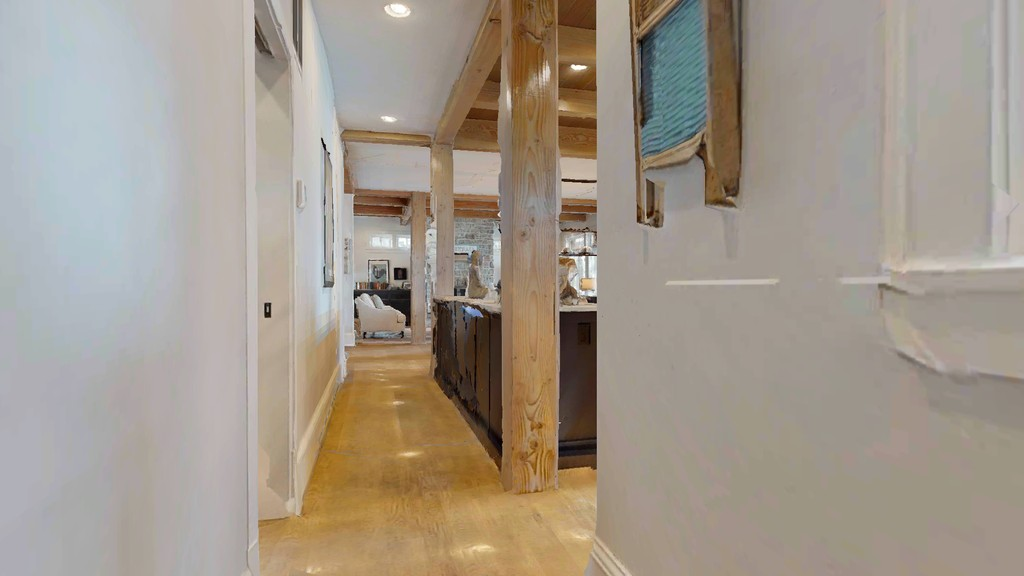
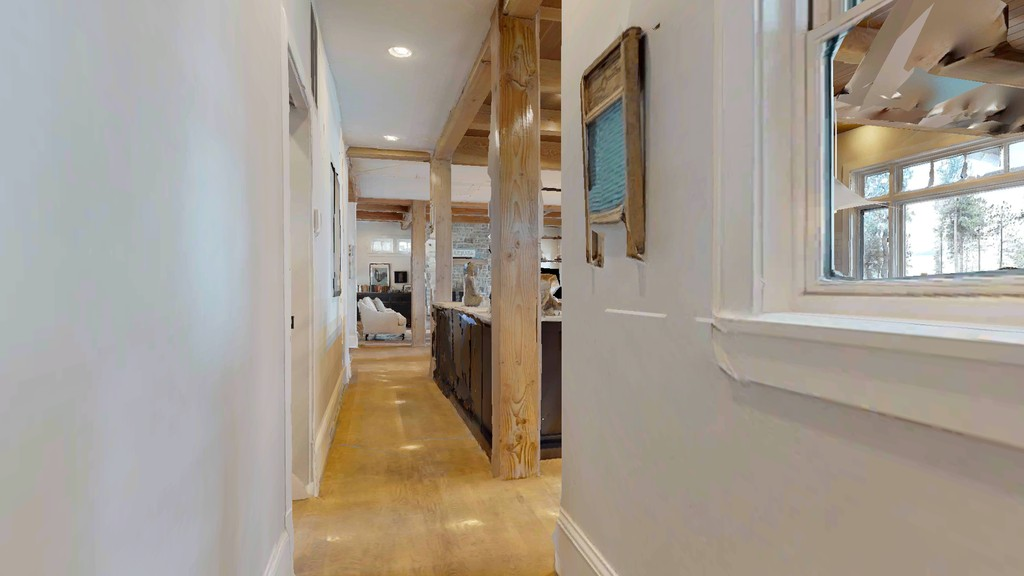
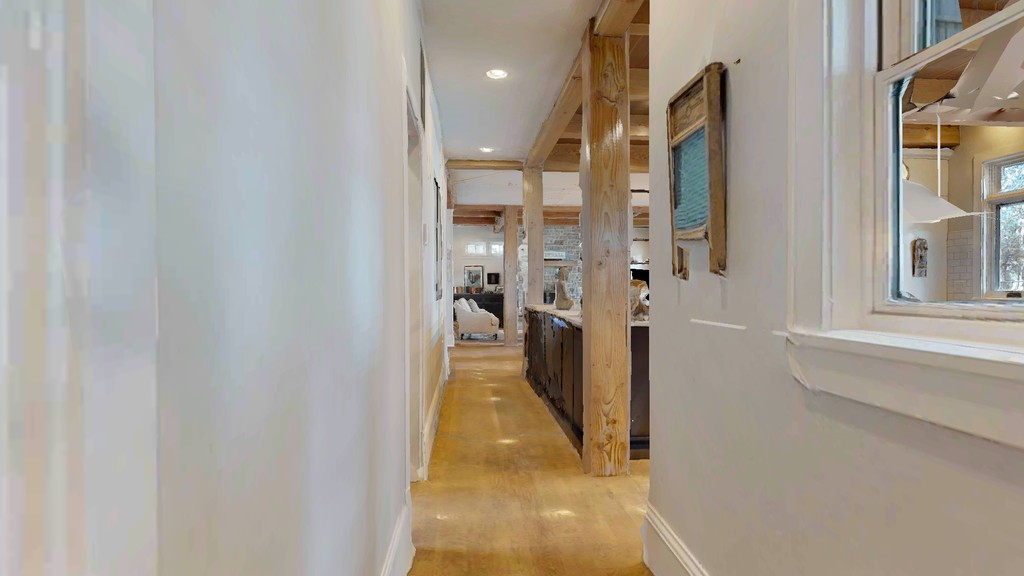
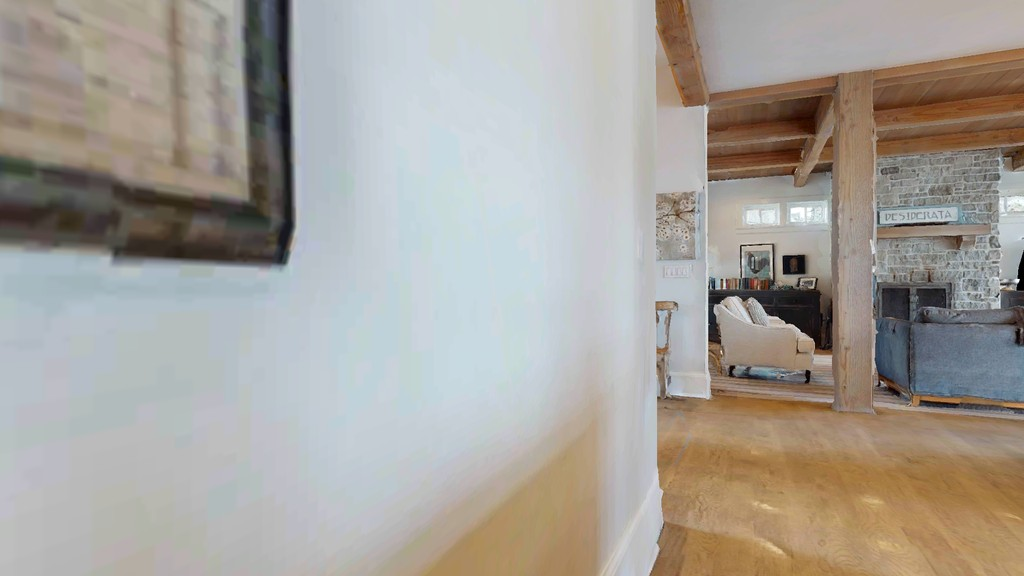
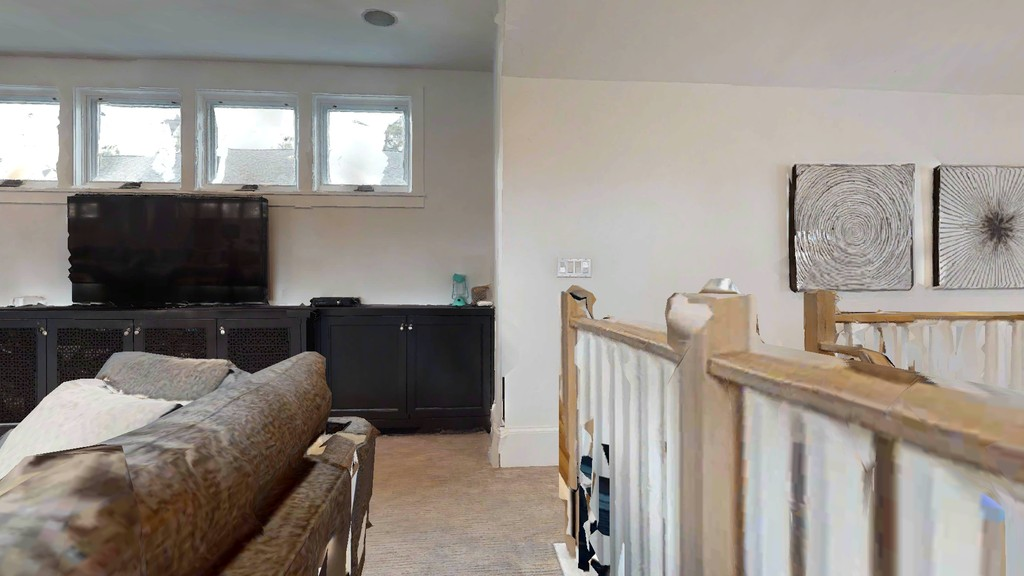

Returned frames can be partial matches. Inspect their images and matched constraints.


Original query ID: a5a88a20-7d66-4b5c-bbfe-3efae2da465a


,label,attributes,states
0,door,[],[open]


No relationship constraint was parsed for this question.
Only explicit labels, attributes and supported relationships are parsed; inspect the plan for omitted context.


Parser limitation: Front is not encoded; the search cannot identify the front door.


,rank,frame_id,score,matched_constraints
0,1,27bb135baf183b4085fc4595c4790057,3.0,Object: door; door: open
1,2,387932289b0bf15fa4596f14eae8bfad,3.0,Object: door; door: open
2,3,3bb00a6bc5eccfc2205f4baecef026c7,3.0,Object: door; door: open
3,4,64506f04ad60ee179372388fcc70e314,3.0,Object: door; door: open
4,5,ae704ebbcc6216da03d5c2f19ffb887b,3.0,Object: door; door: open


Object / ID,Attributes,States
wallwall1,color: light graymaterial: Unknownshape: Unknown,None reported
paintingpainting1,"color: blue, tan, gray, and brownmaterial: Unknownshape: rectangular",None reported
switch plateswitch1,color: whitematerial: Unknownshape: rectangular,None reported
electrical outletoutlet1,color: whitematerial: Unknownshape: rectangular,None reported
windowwindow1,color: whitematerial: Unknownshape: rectangular,None reported
windowwindow2,color: whitematerial: Unknownshape: rectangular,None reported
doordoor1,color: blackmaterial: glass and dark frameshape: rectangular,open
floorindoor_floor1,color: warm brownmaterial: woodshape: Unknown,None reported
floorporch_floor1,color: brownmaterial: woodshape: Unknown,None reported
chairchair1,color: brownmaterial: woodshape: Unknown,None reported

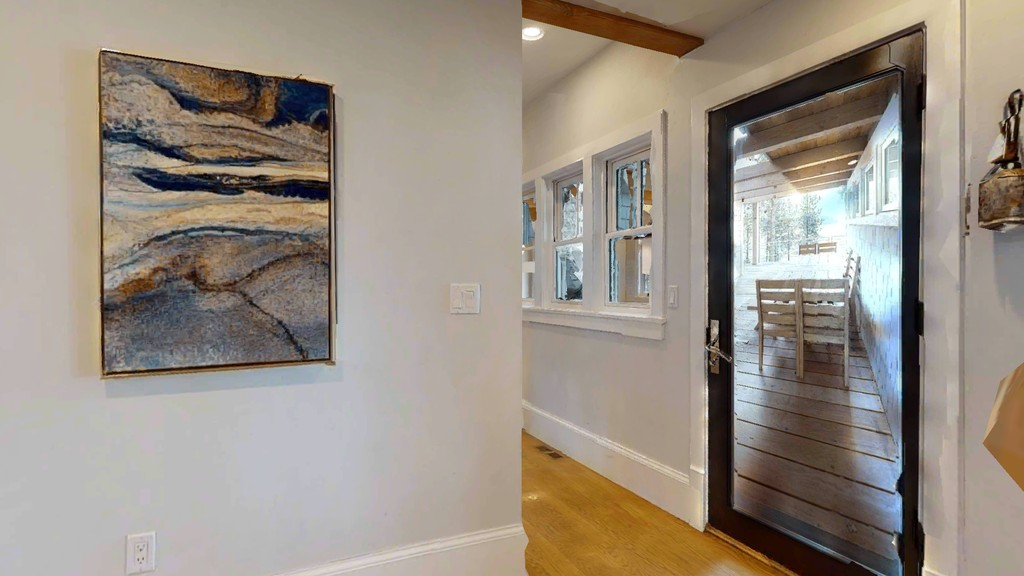
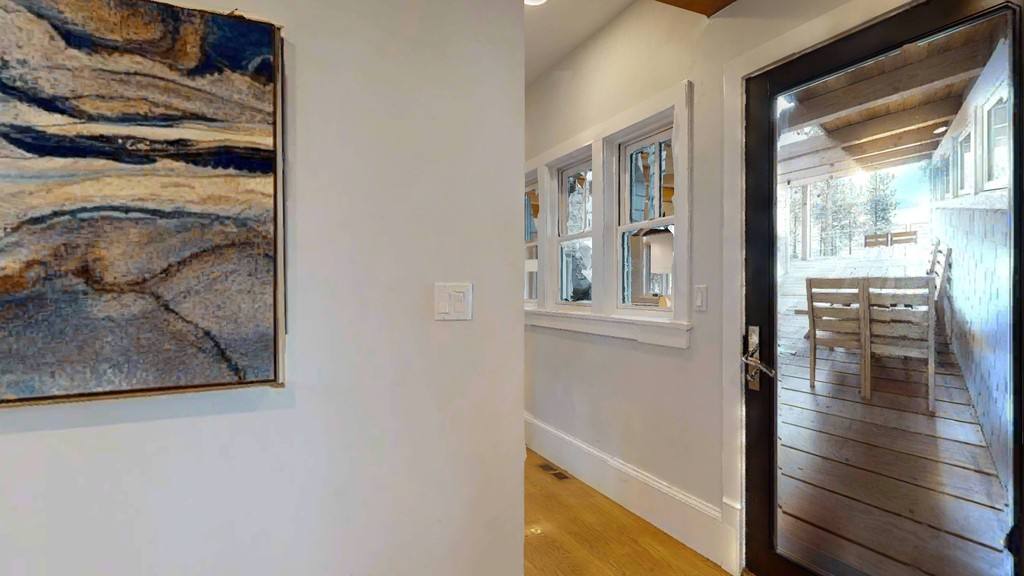
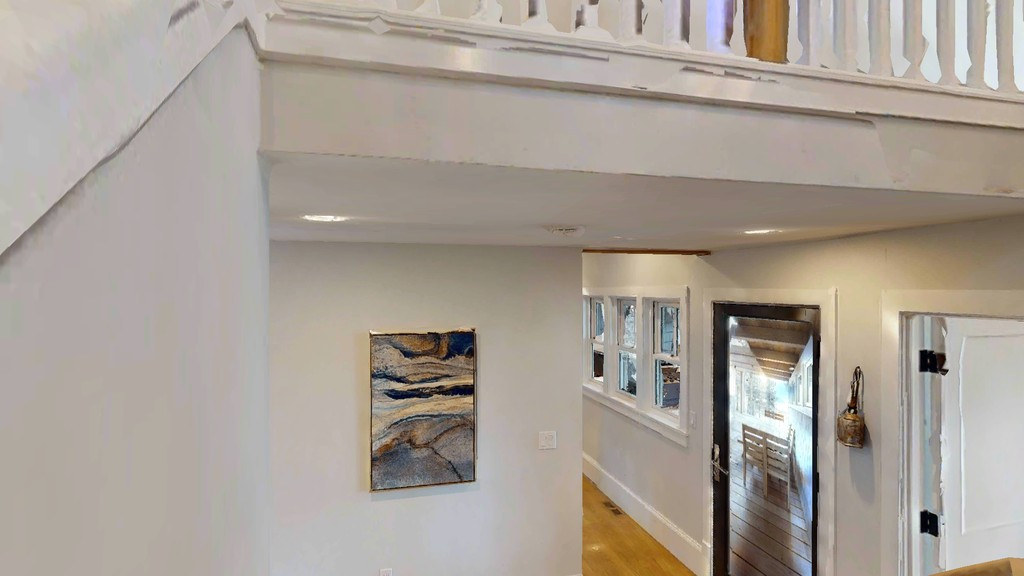
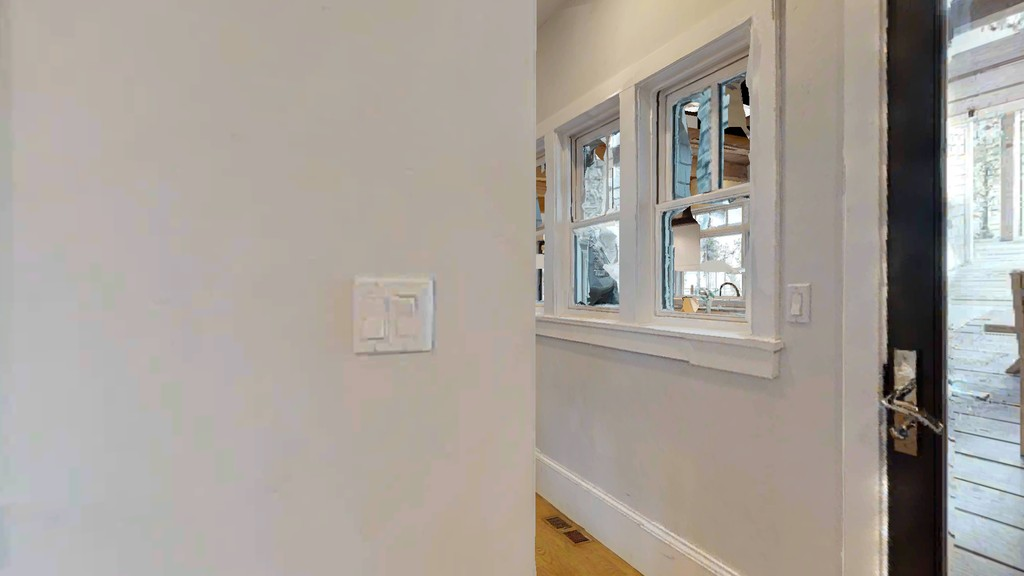
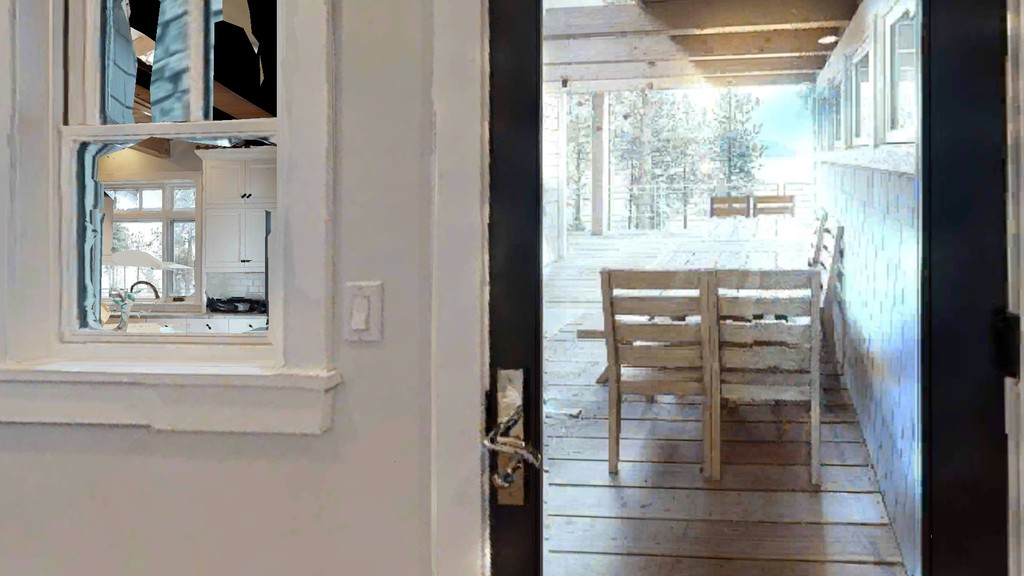

Returned frames can be partial matches. Inspect their images and matched constraints.


Original query ID: deb29a55-6b43-48b6-b974-0c1cb8061cc9


,label,attributes,states
0,tv,[],[on]


No relationship constraint was parsed for this question.
Only explicit labels, attributes and supported relationships are parsed; inspect the plan for omitted context.


Parser limitation: Upstairs is not encoded; the search has no floor/location filter.


,rank,frame_id,score,matched_constraints
0,1,0a59b93e5b178772a02882b7ecccfba1,2.0,Object: tv
1,2,0b7afe3defe2ff1e243a8bb43e5accc8,2.0,Object: tv
2,3,0ddf2b7ff5b7b345b8a051894eb08ff4,2.0,Object: tv
3,4,10949e0dd914de88497d218e76194348,2.0,Object: tv
4,5,11a2927067c4c04e197ea4e8ffef1a37,2.0,Object: tv


Object / ID,Attributes,States
sofasofa1,color: brownmaterial: Unknownshape: Unknown,None reported
cushioncushion1,color: light beigematerial: fabricshape: rectangular,None reported
cushioncushion2,color: graymaterial: fabricshape: rectangular,None reported
televisiontelevision1,color: blackmaterial: Unknownshape: rectangular,screen dark
cabinetcabinet1,color: blackmaterial: Unknownshape: rectangular,None reported
windowwindow1,color: whitematerial: Unknownshape: rectangular,None reported
windowwindow2,color: whitematerial: Unknownshape: rectangular,None reported
windowwindow3,color: whitematerial: Unknownshape: rectangular,None reported
windowwindow4,color: whitematerial: Unknownshape: rectangular,None reported
artworkartwork1,color: graymaterial: Unknownshape: square,None reported

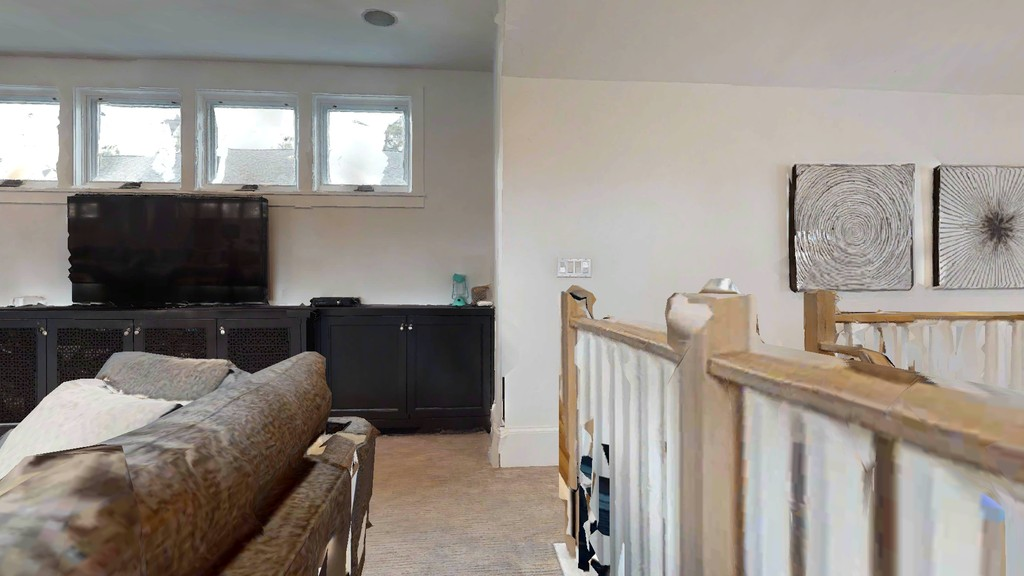
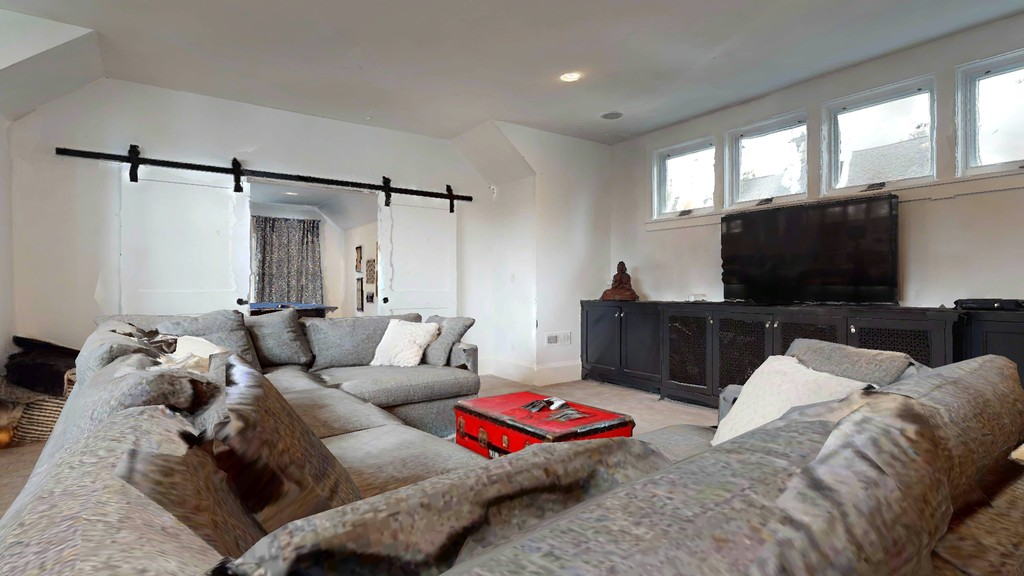
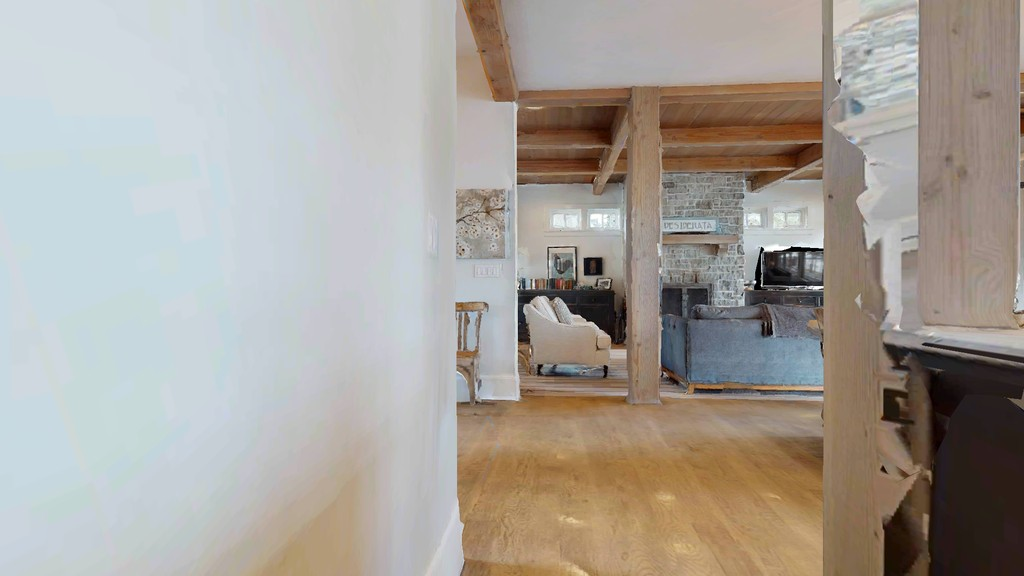
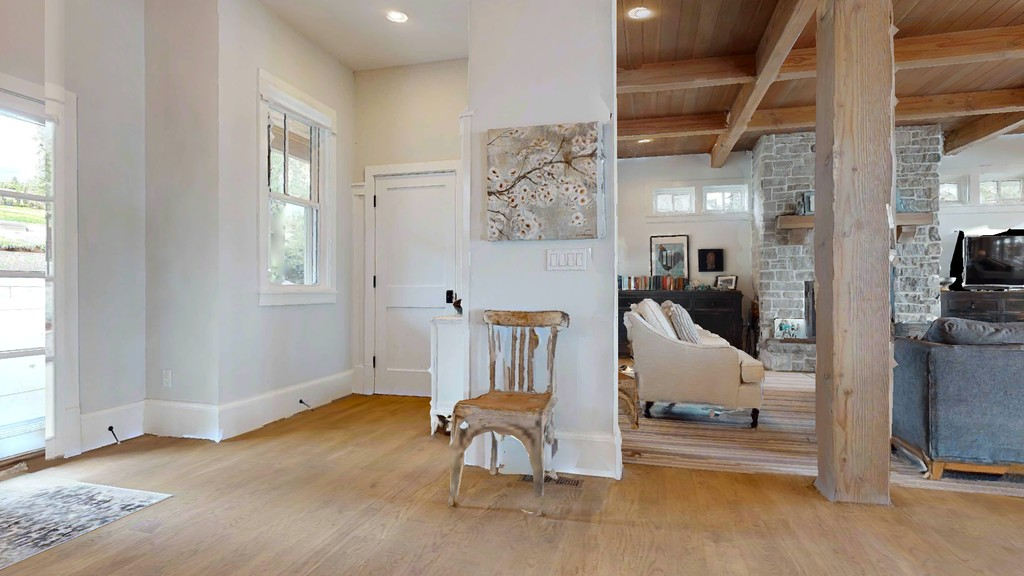
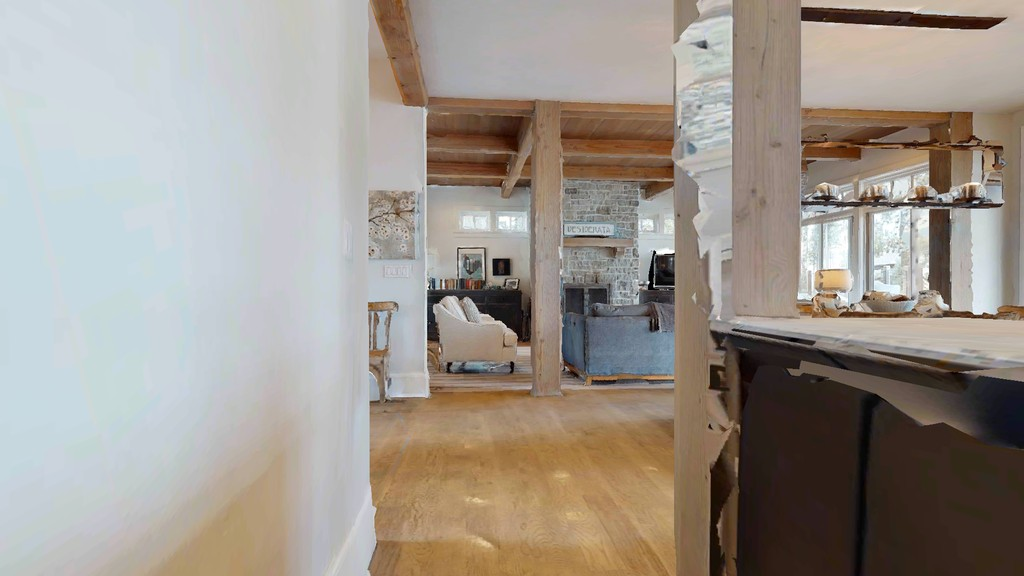

Returned frames can be partial matches. Inspect their images and matched constraints.


Original query ID: 737eae7c-d064-442e-bf18-50792f8b7cc4


,label,attributes,states


No relationship constraint was parsed for this question.
Only explicit labels, attributes and supported relationships are parsed; inspect the plan for omitted context.


,rank,frame_id,score,matched_constraints


No matching visual evidence found.
Returned frames can be partial matches. Inspect their images and matched constraints.


In [6]:
# Presentation: original questions retrieve frames through the Neo4j graph.
query_plans, example_results = gallery.examples(
    examples, retriever=None if SMOKE else retriever, k=TOP_K
)


## Ask your own questions
Edit MY_QUESTIONS and rerun this cell. Each search opens its own connection; no extraction or import is repeated.


,label,attributes,states
0,table,[red],[]


Only explicit labels, attributes and supported relationships are parsed; inspect the plan for omitted context.


,rank,frame_id,score,matched_constraints
0,1,0b7afe3defe2ff1e243a8bb43e5accc8,3.0,Object: table; table: red
1,2,868d9901dd9667a91d9236692b12c562,3.0,Object: table; table: red
2,3,c9ba62fac0ccee203865eff8870e7256,3.0,Object: table; table: red
3,4,013a9f5242f8a75badc03da9380dc888,2.0,Object: table
4,5,0ef54002c1bd64bf8dfdd0326acc0c69,2.0,Object: table


Object / ID,Attributes,States
sofasofa_1,color: gray and beigematerial: fabricshape: sectional,None reported
sofasofa_2,color: graymaterial: fabricshape: cushioned,None reported
coffee tabletable_1,color: redmaterial: unknownshape: rectangular,None reported
cabinetcabinet_1,color: dark graymaterial: unknownshape: long and rectangular,None reported
televisiontelevision_1,color: blackmaterial: unknownshape: rectangular,None reported
sculpturesculpture_1,color: brownmaterial: unknownshape: figurative,None reported
windowwindow_1,color: whitematerial: glassshape: rectangular,None reported
windowwindow_2,color: whitematerial: glassshape: rectangular,None reported
windowwindow_3,color: whitematerial: glassshape: rectangular,None reported
windowwindow_4,color: whitematerial: glassshape: rectangular,None reported

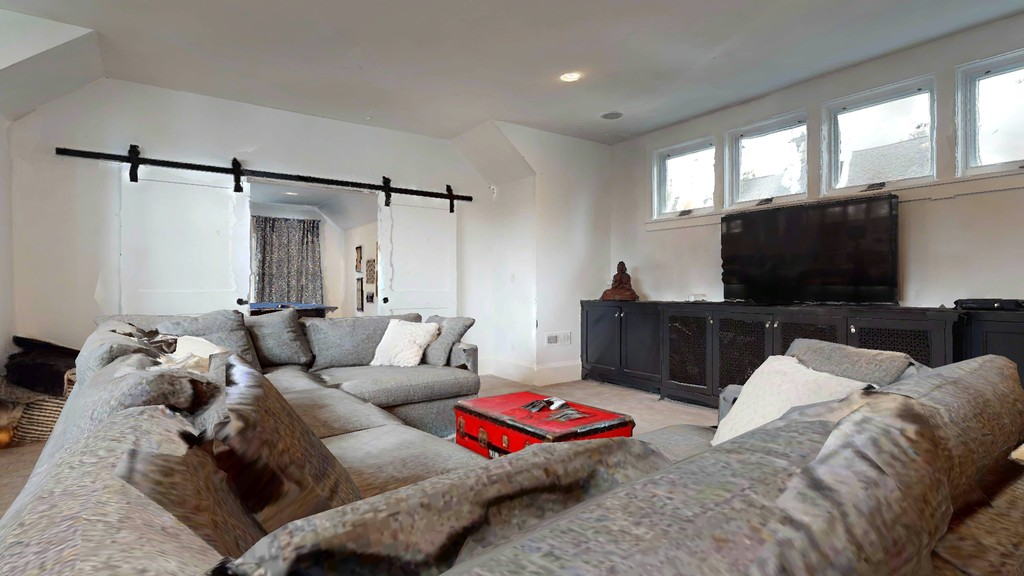
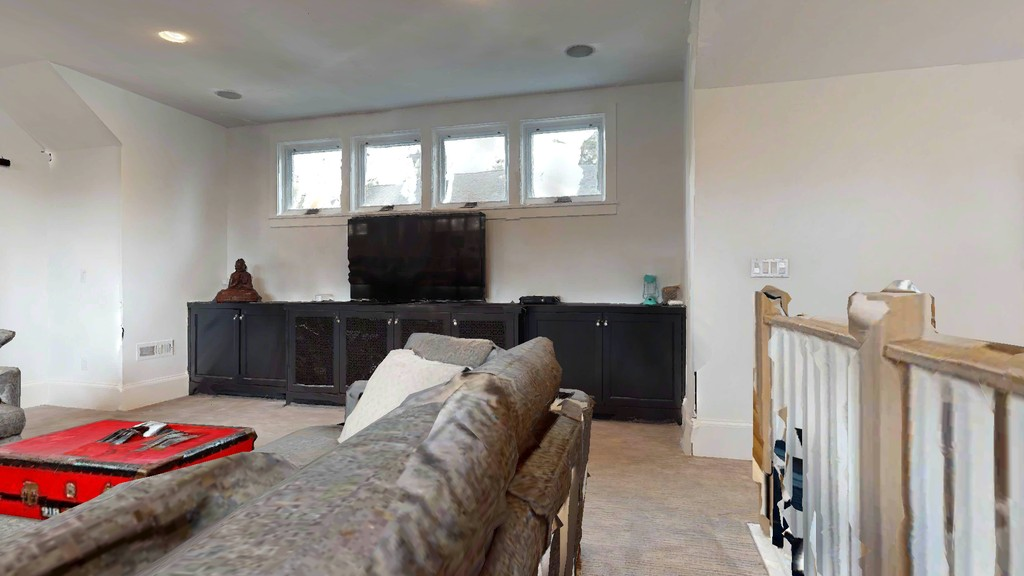
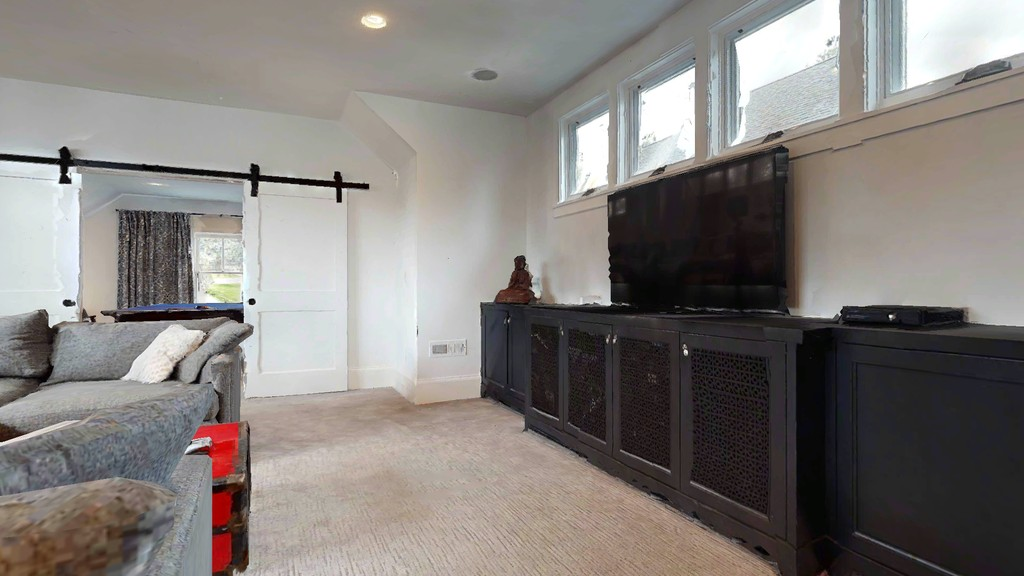
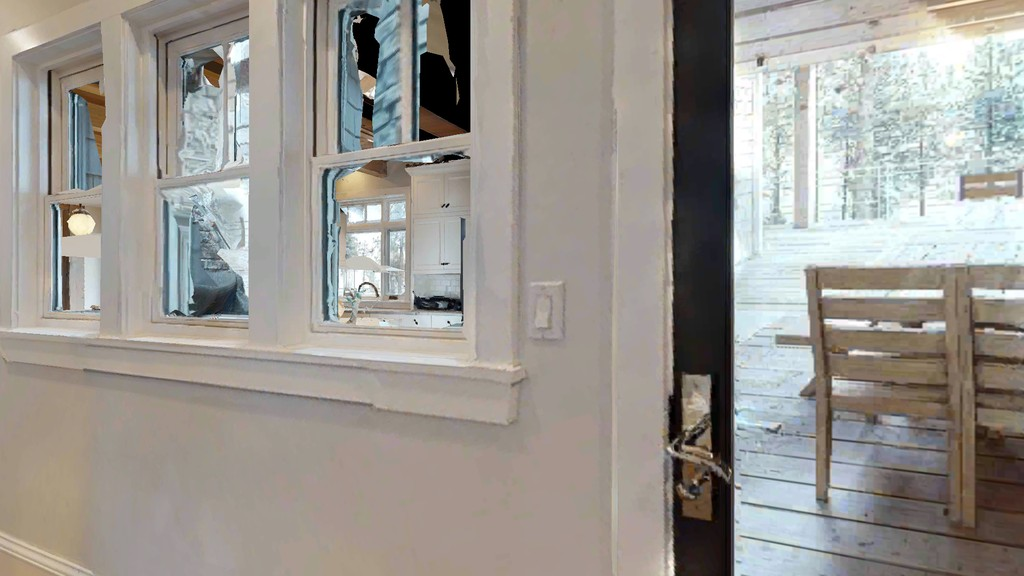
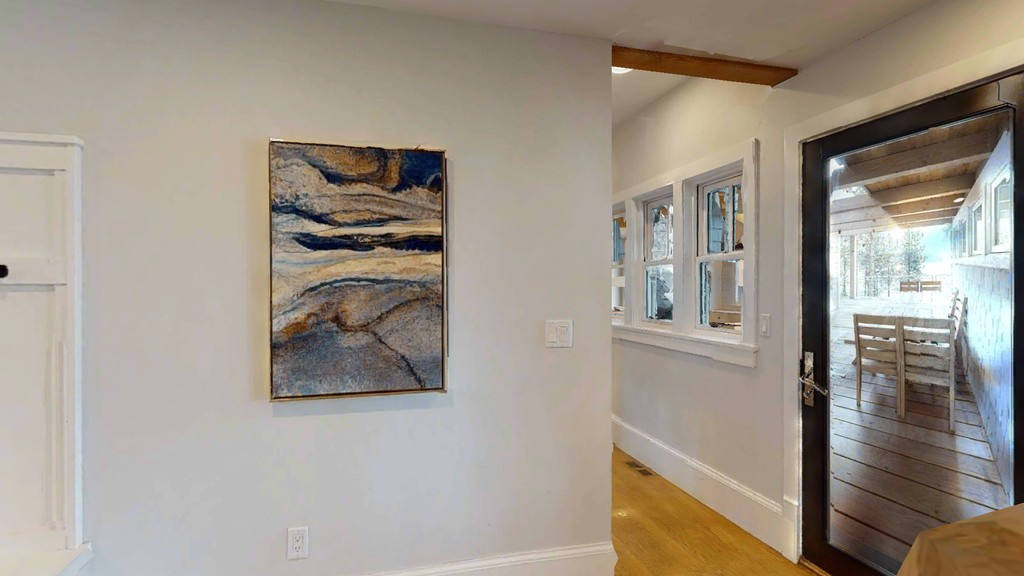

Returned frames can be partial matches. Inspect their images and matched constraints.


,label,attributes,states
0,cabinet,[white],[]


Only explicit labels, attributes and supported relationships are parsed; inspect the plan for omitted context.


,rank,frame_id,score,matched_constraints
0,1,013a9f5242f8a75badc03da9380dc888,3.0,Object: cabinet; cabinet: white
1,2,0e863149e3a71d40e5a0d8c164740822,3.0,Object: cabinet; cabinet: white
2,3,26baf6bab391492dfbdd7a92daed8a97,3.0,Object: cabinet; cabinet: white
3,4,2d0db0f68d627fb58e0ba7fe84a7ba32,3.0,Object: cabinet; cabinet: white
4,5,34aca2607f412b80db6100097590647a,3.0,Object: cabinet; cabinet: white


Object / ID,Attributes,States
windowwindow_1,color: whitematerial: Unknownshape: rectangular,several panes are broken or missing
wallwall_1,color: light beigematerial: Unknownshape: Unknown,None reported
light switchswitch_1,color: whitematerial: Unknownshape: rectangular,None reported
doordoor_1,color: darkmaterial: glass and dark framingshape: rectangular,partly open
deck floordeck_1,color: gray-brownmaterial: woodshape: Unknown,None reported
chairchair_1,color: brownmaterial: woodshape: Unknown,None reported
chairchair_2,color: brownmaterial: woodshape: Unknown,None reported
tabletable_1,color: brownmaterial: woodshape: Unknown,None reported
cabinetcabinet_1,color: whitematerial: Unknownshape: rectangular,None reported
sinksink_1,color: light-coloredmaterial: Unknownshape: Unknown,None reported

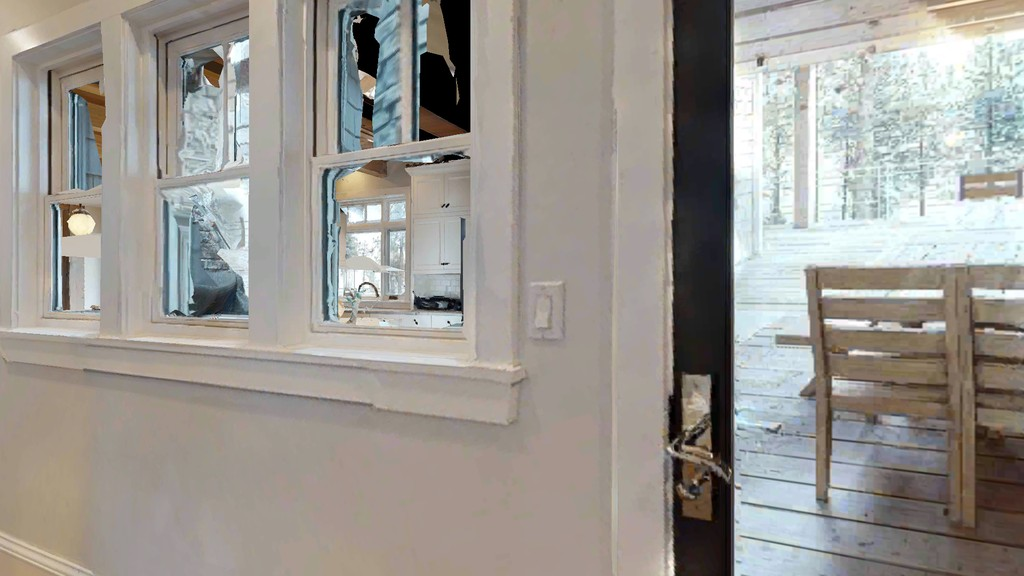
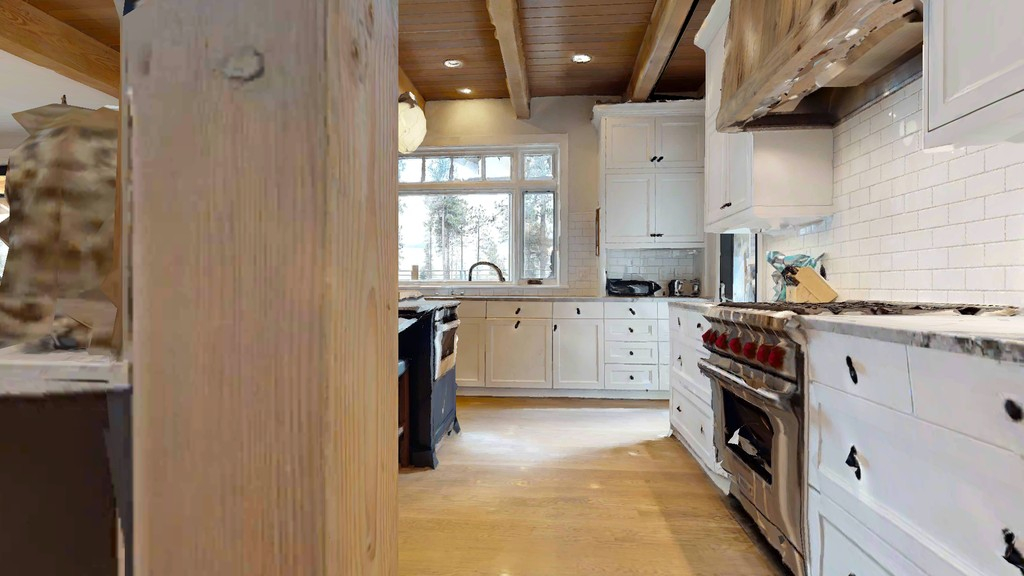
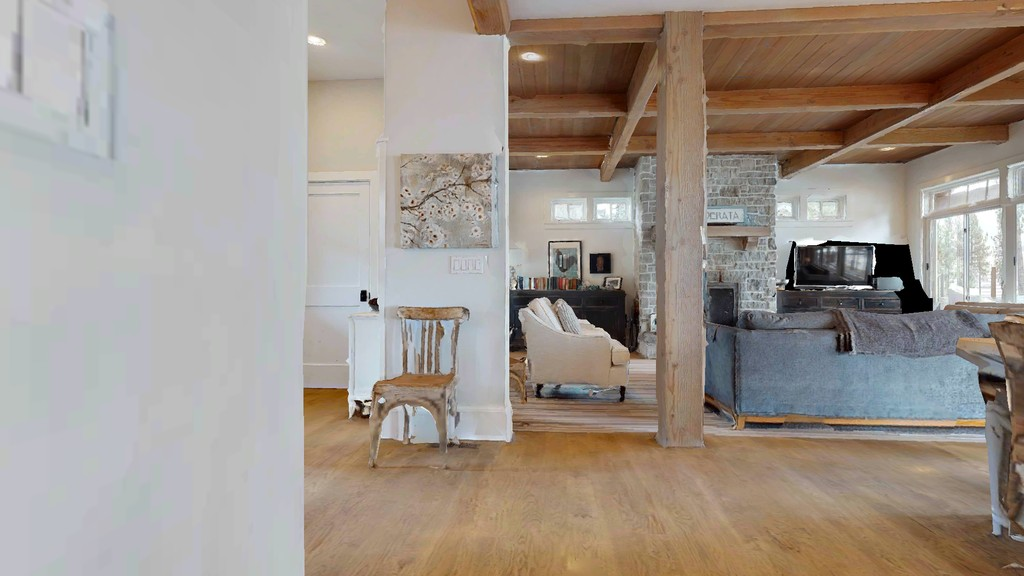
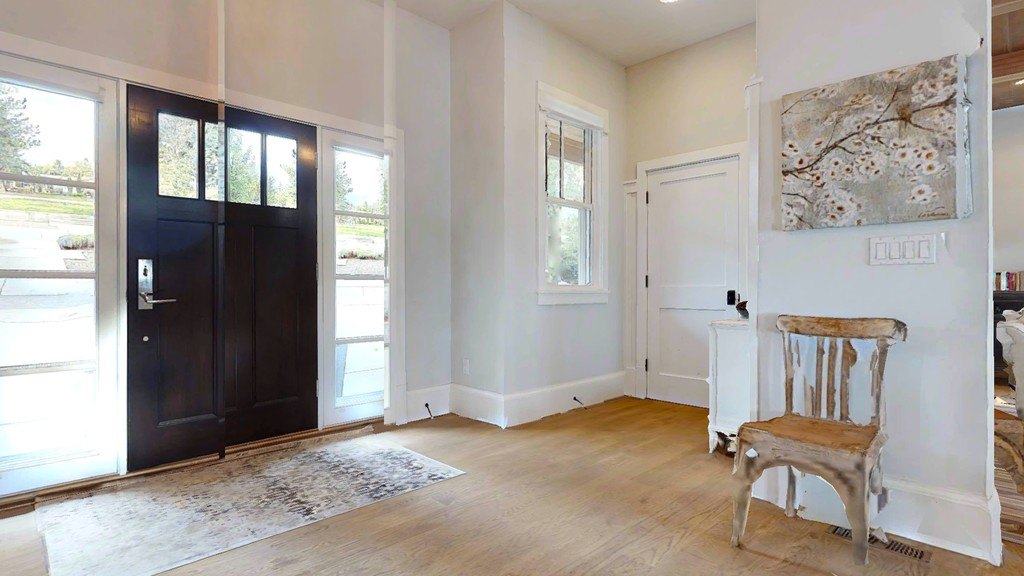
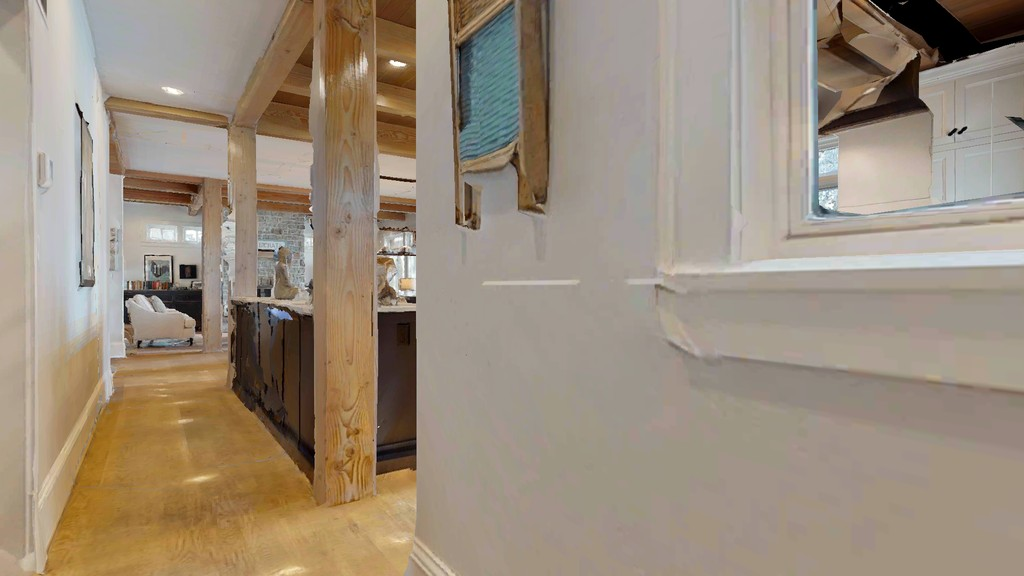

Returned frames can be partial matches. Inspect their images and matched constraints.


In [9]:
# Presentation demo: edit the questions and rerun this cell.
MY_QUESTIONS = [
    "Where is the red coffe table?",
    "where are the white cabinets?",
]
MY_TOP_K = 5

my_results = gallery.ask(MY_QUESTIONS, k=MY_TOP_K)


## Close the connection
The graph remains in Docker’s Neo4j data volume.


In [ ]:
if not SMOKE: driver.close()
print('Graph inspection complete')
